## Backtest

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

bt_url = "/Users/ishika/Documents/Python for Data Science/compact.csv"
bt_df = pd.read_csv(bt_url)
bt_df['date'] = pd.to_datetime(bt_df['date'])
bt_df = bt_df[bt_df['country'] == 'Netherlands'].set_index('date').sort_index()

# include Jan 31, 2022 since your test goes until then
bt_df = bt_df.loc['2020-10-01':'2022-01-31',
                  ['new_cases', 'new_deaths', 'hosp_patients',
                   'people_fully_vaccinated_per_hundred', 'country']]

# Better than fillna(0) for these columns
bt_df['hosp_patients'] = bt_df['hosp_patients'].ffill().fillna(0)
bt_df['people_fully_vaccinated_per_hundred'] = bt_df['people_fully_vaccinated_per_hundred'].ffill().fillna(0)

# Feature Engineering
bt_df['hosp_lag_7'] = bt_df['hosp_patients'].rolling(7).mean().shift(7)
bt_df['hosp_lag_14'] = bt_df['hosp_lag_7'].shift(7)
bt_df['cases_lag_7'] = bt_df['new_cases'].rolling(7).mean().shift(7)
bt_df['cases_lag_14'] = bt_df['cases_lag_7'].shift(14)

# (if you still want a smoothed view, but NO leakage):
bt_df['deaths_smooth_7'] = bt_df['new_deaths'].rolling(7).mean()

# bt_df = bt_df.dropna()

# 2. SPLIT DATA (Time-Based)
# --------------------------
bt_cutoff = '2020-12-01'
bt_features = ['cases_lag_14', 'cases_lag_7',
               'hosp_lag_7', 'hosp_lag_14',
               'people_fully_vaccinated_per_hundred']

bt_target = "deaths_smooth_7"

bt_train = bt_df[bt_df.index < "2020-12-01"]
bt_test  = bt_df["2020-12-01":"2021-01-31"]

bt_train = bt_train.dropna(subset=bt_features + [bt_target])
bt_test  = bt_test.dropna(subset=bt_features + [bt_target])


bt_X_train, bt_y_train = bt_train[bt_features], bt_train[bt_target]
bt_X_test, bt_y_test   = bt_test[bt_features], bt_test[bt_target]


Backtest Linear MAE:        10.67
Backtest Random Forest MAE: 8.11


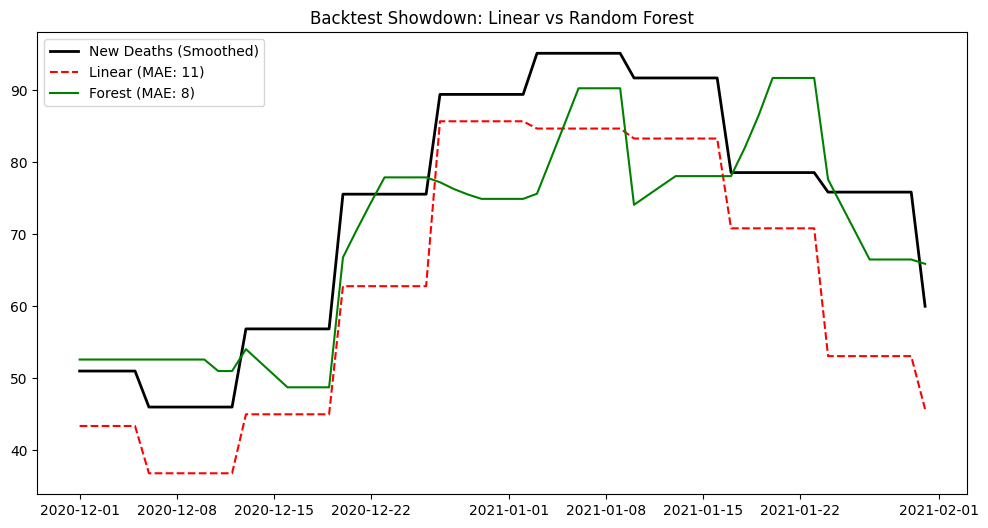

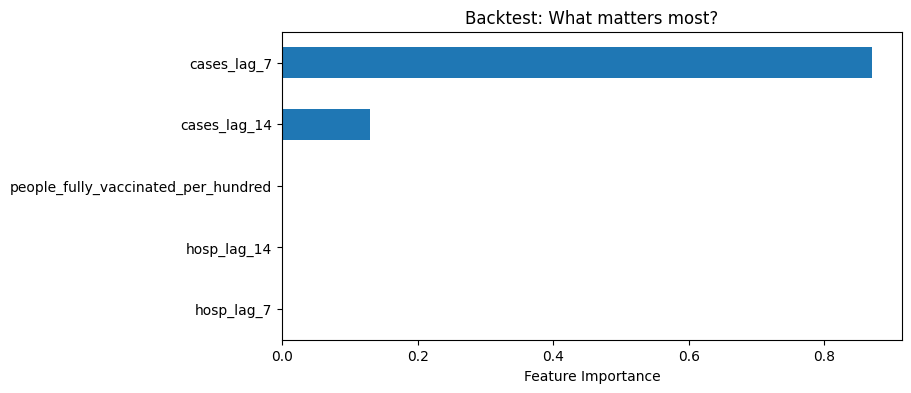

In [2]:
import numpy as np
from sklearn.linear_model import LinearRegression


bt_WINDOW = 7      # Dictates the lag of the scaler
bt_EPS = 1e-6      # A stabilizer value

# Step A: Baseline (Linear Regression)
bt_lr = LinearRegression()
bt_lr.fit(bt_X_train, bt_y_train)
bt_pred_lr = bt_lr.predict(bt_X_test)
bt_mae_lr = mean_absolute_error(bt_y_test, bt_pred_lr)


# Random Forest
bt_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=3,
    min_samples_leaf=5,
    min_samples_split=5,
    random_state=42,
)
bt_rf.fit(bt_X_train, bt_y_train)
bt_pred_rf = bt_rf.predict(bt_X_test)

bt_scaled_pred_rf = np.zeros_like(bt_pred_rf)

# Scaling the predicted value with the target value 7 days behind
for t in range(len(bt_pred_rf)):

    # Not touching the prediction because of the window
    if t < bt_WINDOW + 3:
        bt_scaled_pred_rf[t] = bt_pred_rf[t]
    else:
        # Calculating the mean error for Window-3 : Window
        bt_y_obs_window = bt_y_test[t - bt_WINDOW - 3 : t - bt_WINDOW]
        bt_y_pred_window = bt_pred_rf[t - bt_WINDOW - 3 : t - bt_WINDOW]

        bt_alpha_t = (
            np.mean(bt_y_obs_window)
            / (np.mean(bt_y_pred_window) + bt_EPS)
        )

        # Scaling each day for the error
        bt_scaled_pred_rf[t] = bt_alpha_t * bt_pred_rf[t]

bt_mae_rf = mean_absolute_error(bt_y_test, bt_scaled_pred_rf)

print(f"Backtest Linear MAE:        {bt_mae_lr:.2f}")
print(f"Backtest Random Forest MAE: {bt_mae_rf:.2f}")

# Visualization
plt.figure(figsize=(12, 6))
plt.plot(bt_test.index, bt_y_test, color="black", label="New Deaths (Smoothed)", linewidth=2)
plt.plot(bt_test.index, bt_pred_lr, color="red", linestyle="--",
         label=f"Linear (MAE: {bt_mae_lr:.0f})")
plt.plot(bt_test.index, bt_scaled_pred_rf, color="green",
         label=f"Forest (MAE: {bt_mae_rf:.0f})")
plt.title("Backtest Showdown: Linear vs Random Forest")
plt.legend()
plt.show()

# Opening the black box
bt_importances = pd.Series(
    bt_rf.feature_importances_,
    index=bt_features
).sort_values()

plt.figure(figsize=(8, 4))
bt_importances.plot(kind="barh")
plt.title("Backtest: What matters most?")
plt.xlabel("Feature Importance")
plt.show()


## FORECAST

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

url = "/Users/ishika/Documents/Python for Data Science/compact.csv"
df = pd.read_csv(url)
df['date'] = pd.to_datetime(df['date'])
df = df[df['country'] == 'Netherlands'].set_index('date').sort_index()

# include Jan 31, 2022 since your test goes until then
df = df.loc['2020-10-01':'2022-01-31',
            ['new_cases', 'new_deaths', 'hosp_patients', 'people_fully_vaccinated_per_hundred', 'country']]

# Better than fillna(0) for these columns
df['hosp_patients'] = df['hosp_patients'].ffill()
df['people_fully_vaccinated_per_hundred'] = df['people_fully_vaccinated_per_hundred'].ffill()

# Feature Engineerin
df['hosp_lag_7'] = df['hosp_patients'].rolling(7).mean().shift(7)             
df['hosp_lag_14'] = df['hosp_lag_7'].shift(7)            
df['cases_lag_7'] = df['new_cases'].rolling(7).mean().shift(7)     
df['cases_lag_14'] = df['cases_lag_7'].shift(14) 

#  (if you still want a smoothed view, but NO leakage):
df['deaths_smooth_7'] = df['new_deaths'].rolling(7).mean()    




df = df.dropna()

# 2. SPLIT DATA (Time-Based)
# --------------------------
cutoff = '2021-12-01'
features = ['cases_lag_14', 'cases_lag_7', 'hosp_lag_7', 'hosp_lag_14','people_fully_vaccinated_per_hundred']
# features = ['cases_lag_14', 'cases_smooth_7', 'hosp_lag_7', 'hosp_lag_14']

target = "deaths_smooth_7"  # assignment target replaced with smoothened

train = df[df.index < "2021-12-01"]
test  = df["2021-12-01":"2022-01-31"]

X_train, y_train = train[features], train[target]
X_test, y_test   = test[features], test[target]


Linear MAE:        10.40
Random Forest MAE: 9.92


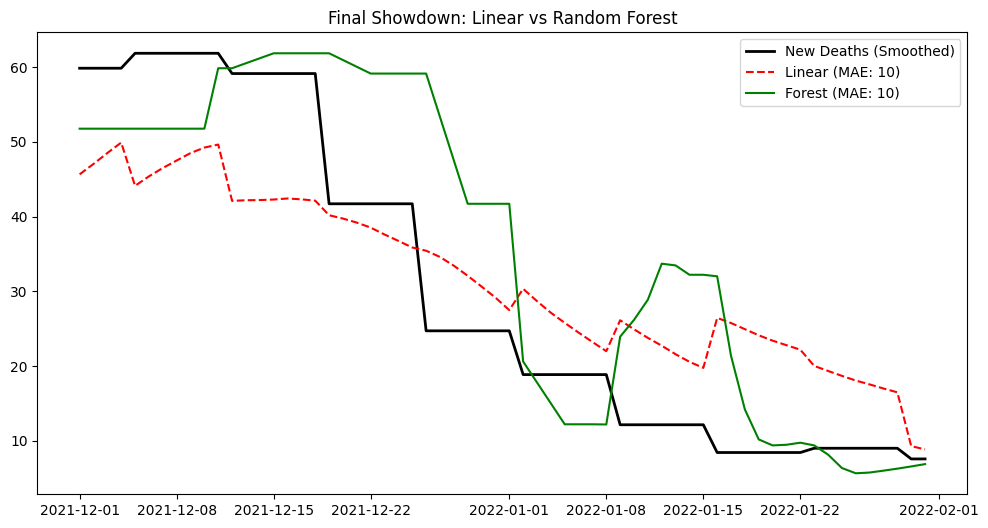

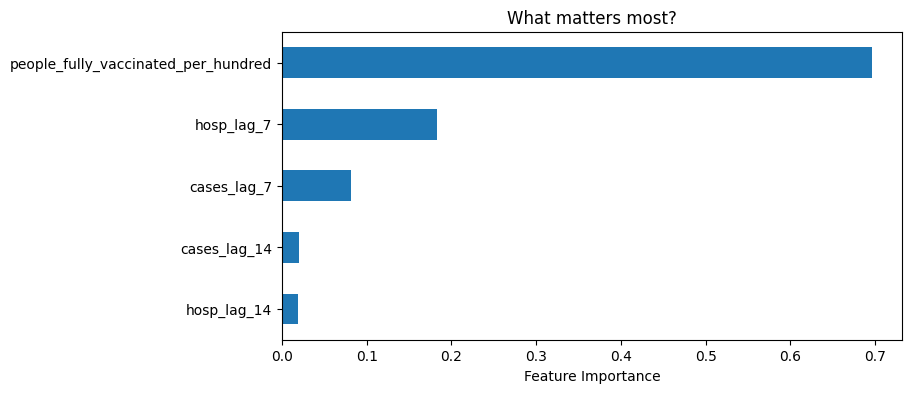

In [4]:
import numpy as np

WINDOW = 7      # Dictates the lag of the scaler
EPS = 1e-6      # A stabilizer value

# Step A: Baseline (Linear Regression)
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)
mae_lr = mean_absolute_error(y_test, pred_lr)


#Random Forest
rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=3,
    min_samples_leaf=5,
    min_samples_split=5,
    random_state=42,
)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

scaled_pred_rf = np.zeros_like(pred_rf)

# Scaling the predicted value with the target value 7 days behind
for t in range(len(pred_rf)):

    # Not touching the prediction because of the window
    if t < WINDOW+3:
        scaled_pred_rf[t] = pred_rf[t]
    else:

        # Calculating the mean error for Window-3 : Window
        y_obs_window = y_test[t-WINDOW-3:t-WINDOW]
        y_pred_window = pred_rf[t-WINDOW-3:t-WINDOW]

        alpha_t = (
            np.mean(y_obs_window)
            / (np.mean(y_pred_window) + EPS)
        )

        # Scaling each day for the error
        scaled_pred_rf[t] = alpha_t * pred_rf[t]

mae_rf = mean_absolute_error(y_test, scaled_pred_rf)
print(f"Linear MAE:        {mae_lr:.2f}")
print(f"Random Forest MAE: {mae_rf:.2f}")

# Visualization
plt.figure(figsize=(12, 6))
plt.plot(test.index, y_test, color="black", label="New Deaths (Smoothed)", linewidth=2)
plt.plot(test.index, pred_lr, color="red", linestyle="--", label=f"Linear (MAE: {mae_lr:.0f})")
plt.plot(test.index, scaled_pred_rf, color="green", label=f"Forest (MAE: {mae_rf:.0f})")
plt.title("Final Showdown: Linear vs Random Forest")
plt.legend()
plt.show()

# Opening the black box
importances = pd.Series(rf.feature_importances_, index=features).sort_values()

plt.figure(figsize=(8, 4))
importances.plot(kind="barh")  
plt.title("What matters most?")
plt.xlabel("Feature Importance")
plt.show()

XGBoost MAE:       6.25


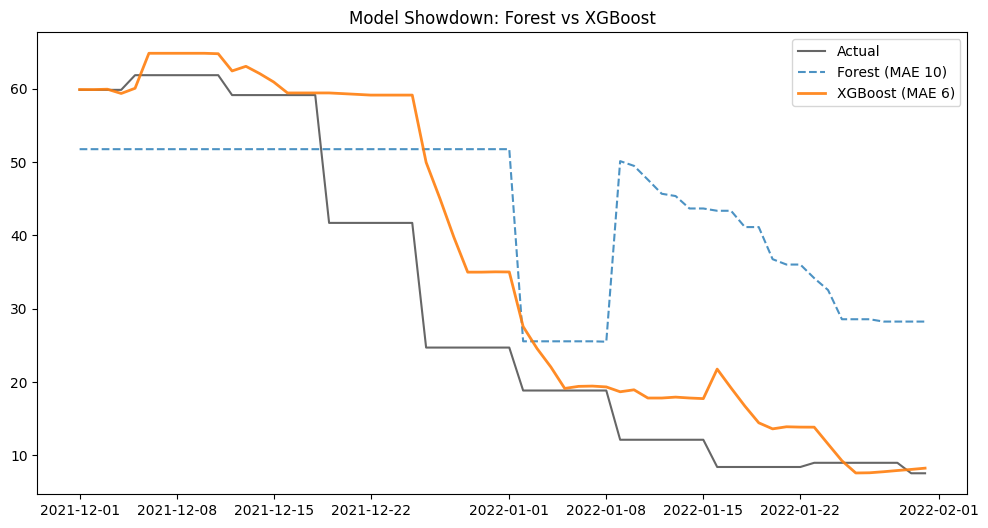

In [5]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=42,
    n_jobs=-1
)

xgb.fit(X_train, y_train)
pred_xgb = xgb.predict(X_test)

scaled_pred_xgb = np.zeros_like(pred_xgb)

for t in range(len(pred_xgb)):
    if t < WINDOW+3:
        scaled_pred_xgb[t] = pred_xgb[t]
    else:
        y_obs_window = y_test[t-WINDOW-3:t-WINDOW]
        y_pred_window = pred_xgb[t-WINDOW-3:t-WINDOW]

        alpha_t = (
            np.mean(y_obs_window)
            / (np.mean(y_pred_window) + EPS)
        )

        scaled_pred_xgb[t] = alpha_t * pred_xgb[t]

mae_xgb = mean_absolute_error(y_test, scaled_pred_xgb)

print(f"XGBoost MAE:       {mae_xgb:.2f}")

plt.figure(figsize=(12, 6))
plt.plot(test.index, y_test, color="black", alpha=0.6, label="Actual")
plt.plot(test.index, pred_rf, linestyle="--", alpha=0.8, label=f"Forest (MAE {mae_rf:.0f})")
plt.plot(test.index, scaled_pred_xgb, linewidth=2, alpha=0.9, label=f"XGBoost (MAE {mae_xgb:.0f})")
plt.title("Model Showdown: Forest vs XGBoost")
plt.legend()
plt.show()


In [6]:
# --------------------------------------------------
# JANUARY 2022 EXPORT (XGBOOST – NETHERLANDS)
# --------------------------------------------------

# Use XGBOOST (scaled) predictions
pred_best = scaled_pred_xgb

# January 2022 mask
jan_mask = (
    (X_test.index >= "2022-01-01") &
    (X_test.index <= "2022-01-31")
)

jan_dates = X_test.index[jan_mask]
jan_predictions = pred_best[jan_mask]

final_predictions = pd.DataFrame({
    "Date": jan_dates,
    "Region": "Netherlands",
    "Predicted deaths": jan_predictions,
    "Actual deaths": y_test.loc[jan_dates].values
})

# Round predictions to integers
final_predictions["Predicted deaths"] = (
    final_predictions["Predicted deaths"].round(0).astype(int)
)

# Save CSV (downloadable file)
final_predictions.to_csv(
    "Netherlands_Jan2022_Predicted_Deaths_XGB.csv",
    index=False
)

print(final_predictions.head())
print(final_predictions.tail())
print(len(final_predictions))  # should be 31
print("File downloaded successfully!")


        Date       Region  Predicted deaths  Actual deaths
0 2022-01-01  Netherlands                35      24.714286
1 2022-01-02  Netherlands                28      18.857143
2 2022-01-03  Netherlands                25      18.857143
3 2022-01-04  Netherlands                22      18.857143
4 2022-01-05  Netherlands                19      18.857143
         Date       Region  Predicted deaths  Actual deaths
26 2022-01-27  Netherlands                 8       9.000000
27 2022-01-28  Netherlands                 8       9.000000
28 2022-01-29  Netherlands                 8       9.000000
29 2022-01-30  Netherlands                 8       7.571429
30 2022-01-31  Netherlands                 8       7.571429
31
File downloaded successfully!
